# 15. 진단 분석: 사람별 성능, 묶음 안/밖 오류, 클립 8장 일관성

새 학습 없이, CV 2단계와 같은 36개 실행(letterbox·stretch·aspect384·ccrop × seed 3 × fold 3)과 공식 Val의 E01(Scratch)·E04(Full)의 예측표로 분석합니다. Test는 쓰지 않습니다. 지표 정의는 예측을 만들기 전에 `experiments/ANA/PLAN.md`에 적었습니다.

- **A1 사람별 성능**: 사람마다 그 사람이 가진 클래스만으로 Recall 평균(사람 Macro Recall)
- **A2 묶음 안/밖 오류**: 오답 중 같은 운동 묶음(맨몸·바벨덤벨·기구) 안에서 틀린 비율
- **A3 클립 8장 일관성**: 같은 클립(카메라 2대 × 4시점) 안에서 예측이 얼마나 같은가

진단이므로 결과로 전처리·모델 선택을 바꾸지 않습니다.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score
import json

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT / "src"))
from common import FIGURES, GROUPS, CLASS_TO_GROUP, class_names, set_korean_font

print("font:", set_korean_font())
pd.set_option("display.width", 220)
NAMES = class_names()
EXP = ROOT / "experiments"
PRED = EXP / "ANA" / "pred"
PRE, SEEDS, FOLDS = ("letterbox", "stretch", "aspect384", "ccrop"), (42, 43, 44), (1, 2, 3)
rid = lambda p, s, f: f"CV1-{p}-f{f}" if s == 42 else f"CV2-{p}-s{s}-f{f}"  # noqa: E731

def load(run_id, strat="full"):
    df = pd.read_csv(PRED / f"{run_id}__train.csv")
    sm = json.loads((EXP / run_id / strat / "summary.json").read_text(encoding="utf-8"))
    f1 = f1_score(df.target_id, df.pred, labels=list(range(12)), average="macro", zero_division=0)
    assert abs(f1 - sm["val"]["macro_f1"]) < 1e-6, (run_id, f1, sm["val"]["macro_f1"])  # 예측표가 학습 기록과 같은지
    return df

frames = []
for p in PRE:
    for s in SEEDS:
        for f in FOLDS:
            d = load(rid(p, s, f)); d["전처리"], d["seed"], d["fold"] = p, s, f
            frames.append(d)
cv = pd.concat(frames, ignore_index=True)
off = {"E01 Scratch": load("E01", "scratch"), "E04 Full": load("E04")}
folds = pd.read_csv(ROOT / "data" / "splits" / "cv3_folds.csv")
assert cv.groupby(["전처리", "seed"]).person_id.nunique().eq(19).all()  # seed·전처리마다 19명 모두 한 번씩
print(len(cv), "rows,", cv.groupby(["전처리", "seed", "fold"]).ngroups, "runs, 예측표 F1 = 학습 기록 F1 확인")

font: Malgun Gothic


115008 rows, 36 runs, 예측표 F1 = 학습 기록 F1 확인


## A1. 사람별 성능(보유 클래스 기준)

In [2]:
def person_scores(d):
    rec = d.groupby(["person_id", "target_id"]).correct.mean()
    return pd.DataFrame({"Macro Recall": rec.groupby(level=0).mean(), "Acc": d.groupby("person_id").correct.mean(),
                         "클래스 수": rec.groupby(level=0).size()})

ps = pd.concat([person_scores(g).assign(전처리=p, seed=s) for (p, s), g in cv.groupby(["전처리", "seed"])]).reset_index()
info = folds.set_index("person_id")[["fold", "group"]]
own = cv[(cv["전처리"] == "letterbox") & (cv.seed == 42)].groupby("person_id").target_id.unique().map(lambda v: ", ".join(NAMES[c] for c in sorted(v)))
tab = ps.groupby(["person_id", "전처리"])["Macro Recall"].agg(["mean", "std"]).unstack("전처리")
show = pd.DataFrame({p: tab[("mean", p)].round(3).astype(str) + "±" + tab[("std", p)].round(3).astype(str) for p in PRE})
show = info.join(show).join(own.rename("보유 클래스")).sort_values(["group", "fold"])
show

,fold,group,letterbox,stretch,aspect384,ccrop,보유 클래스
person_id,,,,,,,
Z85,1,기구,0.993±0.007,0.997±0.001,0.994±0.003,0.995±0.006,"딥스, 랫풀 다운, 로잉머신, 케이블 크런치"
Z88,1,기구,0.998±0.002,0.999±0.001,0.998±0.002,0.998±0.0,"딥스, 랫풀 다운, 로잉머신, 케이블 크런치"
Z89,1,기구,0.97±0.02,0.996±0.0,0.996±0.0,0.982±0.016,"딥스, 랫풀 다운, 로잉머신, 케이블 크런치"
Z86,2,기구,0.994±0.002,0.993±0.001,0.997±0.001,0.994±0.0,"딥스, 랫풀 다운, 로잉머신, 케이블 크런치"
Z90,2,기구,0.991±0.006,0.993±0.001,0.996±0.0,0.995±0.002,"딥스, 랫풀 다운, 로잉머신, 케이블 크런치"
Z82,3,기구,0.973±0.041,1.0±0.0,0.997±0.003,1.0±0.0,"딥스, 랫풀 다운, 로잉머신, 케이블 크런치"
Z87,3,기구,0.986±0.022,0.995±0.005,0.997±0.004,0.999±0.002,"딥스, 랫풀 다운, 로잉머신, 케이블 크런치"
Z3,1,바닥,0.924±0.029,0.919±0.015,0.946±0.028,0.945±0.02,"Y - Exercise, 니푸쉬업, 라잉 레그 레이즈, 바이시클 크런치"
Z56,1,바닥,0.826±0.06,0.821±0.056,0.864±0.031,0.902±0.059,"Y - Exercise, 니푸쉬업, 라잉 레그 레이즈, 바이시클 크런치"


In [3]:
lb = ps[ps["전처리"] == "letterbox"]
spread = pd.DataFrame({p: {"사람 간 sd(19명, seed 평균 점수)": ps[ps["전처리"] == p].groupby("person_id")["Macro Recall"].mean().std(ddof=1),
                           "seed 간 sd(사람마다, 평균)": ps[ps["전처리"] == p].groupby("person_id")["Macro Recall"].std(ddof=1).mean(),
                           "최저 사람 점수": ps[ps["전처리"] == p].groupby("person_id")["Macro Recall"].mean().min(),
                           "0.80 미만 사람 수": int((ps[ps["전처리"] == p].groupby("person_id")["Macro Recall"].mean() < 0.80).sum())}
                       for p in PRE})
grp = ps.merge(info, left_on="person_id", right_index=True).groupby(["group", "전처리"])["Macro Recall"].mean().unstack().reindex(columns=PRE)
display(spread.round(3)); display(grp.round(3))

,letterbox,stretch,aspect384,ccrop
"사람 간 sd(19명, seed 평균 점수)",0.153,0.137,0.129,0.129
"seed 간 sd(사람마다, 평균)",0.025,0.016,0.016,0.014
최저 사람 점수,0.576,0.641,0.671,0.666
0.80 미만 사람 수,6.000,6.000,6.000,6.000


전처리,letterbox,stretch,aspect384,ccrop
group,,,,
기구,0.986,0.996,0.996,0.995
바닥,0.916,0.908,0.935,0.937
바닥+기구,0.935,0.942,0.935,0.938
바벨·덤벨,0.649,0.688,0.710,0.708


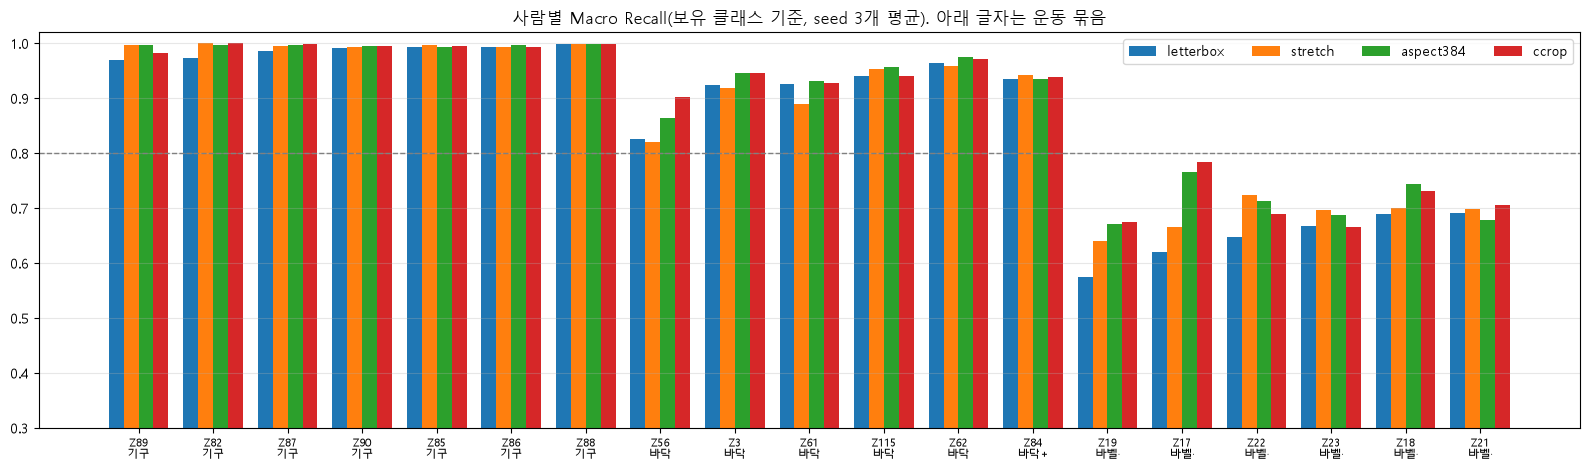

In [4]:
m = ps.groupby(["person_id", "전처리"])["Macro Recall"].mean().unstack()[list(PRE)]
m = m.join(info).sort_values(["group", "letterbox"])
fig, ax = plt.subplots(figsize=(16, 4.8))
x = np.arange(len(m))
for k, p in enumerate(PRE):
    ax.bar(x + (k - 1.5) * 0.2, m[p], 0.2, label=p)
ax.set_xticks(x); ax.set_xticklabels([f"{i}\n{g[:3]}" for i, g in zip(m.index, m.group)], fontsize=8)
ax.set_ylim(0.3, 1.02); ax.axhline(0.8, color="gray", ls="--", lw=1); ax.legend(ncol=4); ax.grid(alpha=.3, axis="y")
ax.set_title("사람별 Macro Recall(보유 클래스 기준, seed 3개 평균). 아래 글자는 운동 묶음")
plt.tight_layout(); plt.savefig(FIGURES / "ana_person.png", dpi=110); plt.show()

## A2. 묶음 안/밖 오분류

In [5]:
def group_err(d):
    w = d[~d.correct]
    same = (w.target_id.map(CLASS_TO_GROUP) == w.pred.map(CLASS_TO_GROUP))
    return pd.Series({"이미지": len(d), "오답": len(w), "묶음 안 오답": int(same.sum()), "묶음 밖 오답": int((~same).sum()),
                      "묶음 안 비율": same.mean() if len(w) else np.nan})

per_run = cv.groupby(["전처리", "seed", "fold"]).apply(group_err, include_groups=False)
agg = per_run.groupby("전처리")[["이미지", "오답", "묶음 안 오답", "묶음 밖 오답"]].sum().reindex(PRE)
agg["묶음 안 비율(합계)"] = agg["묶음 안 오답"] / agg["오답"]
agg["실행별 범위"] = per_run.groupby("전처리")["묶음 안 비율"].agg(lambda v: f"{v.min():.3f}~{v.max():.3f}").reindex(PRE)
offt = pd.DataFrame({k: group_err(v) for k, v in off.items()}).T
display(agg); display(offt)

,이미지,오답,묶음 안 오답,묶음 밖 오답,묶음 안 비율(합계),실행별 범위
전처리,,,,,,
letterbox,28752.0,3413.0,3403.0,10.0,0.997070,0.991~1.000
stretch,28752.0,2996.0,2990.0,6.0,0.997997,0.990~1.000
aspect384,28752.0,2544.0,2541.0,3.0,0.998821,0.996~1.000
ccrop,28752.0,2391.0,2389.0,2.0,0.999164,0.996~1.000


,이미지,오답,묶음 안 오답,묶음 밖 오답,묶음 안 비율
E01 Scratch,1440.0,291.0,291.0,0.0,1.0
E04 Full,1440.0,193.0,193.0,0.0,1.0


In [6]:
def out_detail(d, label):
    w = d[~d.correct]
    w = w[w.target_id.map(CLASS_TO_GROUP) != w.pred.map(CLASS_TO_GROUP)]
    return (w.assign(정답=w.true_name, 예측=w.pred_name).groupby(["정답", "예측"]).size().sort_values(ascending=False)
            .head(8).rename(label))

display(out_detail(cv[cv["전처리"] == "letterbox"], "letterbox 9회 합계 묶음 밖 오답").to_frame())
for k, v in off.items():
    display(out_detail(v, f"{k} 묶음 밖 오답").to_frame())

letterbox 9회 합계 묶음 밖 오답
정답           예측                                 
Y - Exercise 덤벨 벤트오버 로우                        4
니푸쉬업         바벨 런지                             2
Y - Exercise 바벨 런지                             1
랫풀 다운        바벨 데드리프트                          1
             바벨 로우                             1
케이블 크런치      바벨 데드리프트                          1

,,E01 Scratch 묶음 밖 오답
정답,예측,


,,E04 Full 묶음 밖 오답
정답,예측,


## A3. 클립 8장 일관성

In [7]:
def clip_stats(d):
    rows = []
    for cid, g in d.groupby("clip_id"):
        vc = g.pred.value_counts()
        same_t = [c.pred.nunique() == 1 for _, c in g.groupby("frame_no")]                       # 같은 순간·다른 카메라 2장
        same_v = [c.pred.nunique() == 1 for _, c in g.groupby("camera") if len(c) == 2]          # 같은 카메라·다른 순간 2장
        rows.append({"clip_id": cid, "정답": g.target_id.iloc[0], "장수": len(g), "카메라 수": g.camera.nunique(), "시점 수": g.frame_no.nunique(),
                     "예측 종류 수": len(vc), "일치율": vc.iloc[0] / len(g),
                     "같은 순간 2장 일치": np.mean(same_t), "같은 카메라 2장 일치": np.mean(same_v),
                     "유형": "모두 정답" if g.correct.all() else ("모두 오답" if (~g.correct).all() else "섞임")})
    return pd.DataFrame(rows)

cs = pd.concat([clip_stats(g).assign(전처리=p, seed=s, fold=f) for (p, s, f), g in cv.groupby(["전처리", "seed", "fold"])], ignore_index=True)
print("클립 장수:", cs["장수"].value_counts().to_dict(), "/ 카메라 수:", cs["카메라 수"].value_counts().to_dict(), "/ 시점 수:", cs["시점 수"].value_counts().to_dict())
print("구조: 한 클립 = 4개 시점 × 시점마다 다른 카메라 2대(카메라 5대 중 3대 2장, 2대 1장)")
summ = cs.groupby("전처리").agg(클립=("clip_id", "size"), 일치율=("일치율", "mean"), 같은_순간_2장_일치=("같은 순간 2장 일치", "mean"),
                              같은_카메라_2장_일치=("같은 카메라 2장 일치", "mean"), 예측_종류_수=("예측 종류 수", "mean")).reindex(PRE)
typ = pd.crosstab(cs["전처리"], cs["유형"], normalize="index").reindex(PRE)
display(summ.round(3)); display(typ.round(3))

클립 장수: {8: 14376} / 카메라 수: {5: 14376} / 시점 수: {4: 14376}
구조: 한 클립 = 4개 시점 × 시점마다 다른 카메라 2대(카메라 5대 중 3대 2장, 2대 1장)


,클립,일치율,같은_순간_2장_일치,같은_카메라_2장_일치,예측_종류_수
전처리,,,,,
letterbox,3594,0.908,0.867,0.890,1.445
stretch,3594,0.915,0.877,0.909,1.401
aspect384,3594,0.931,0.903,0.910,1.339
ccrop,3594,0.939,0.916,0.914,1.303


유형,모두 오답,모두 정답,섞임
전처리,,,
letterbox,0.015,0.698,0.287
stretch,0.011,0.714,0.275
aspect384,0.008,0.742,0.250
ccrop,0.017,0.755,0.229


In [8]:
order = [c for g in GROUPS.values() for c in g]
lbc = cs[cs["전처리"] == "letterbox"]
bycls = lbc.groupby("정답").agg(일치율=("일치율", "mean"), 같은_순간=("같은 순간 2장 일치", "mean"), 같은_카메라=("같은 카메라 2장 일치", "mean"),
                               모두_정답=("유형", lambda v: (v == "모두 정답").mean()), 섞임=("유형", lambda v: (v == "섞임").mean()),
                               모두_오답=("유형", lambda v: (v == "모두 오답").mean())).reindex(order)
bycls.index = [f"{c} {NAMES[c]}" for c in order]
bycls.round(3)

,일치율,같은_순간,같은_카메라,모두_정답,섞임,모두_오답
0 Y - Exercise,0.951,0.950,0.924,0.778,0.222,0.000
1 니푸쉬업,0.999,0.999,1.000,0.994,0.006,0.000
4 라잉 레그 레이즈,0.898,0.869,0.847,0.587,0.413,0.000
10 바이시클 크런치,0.829,0.769,0.750,0.361,0.639,0.000
2 덤벨 벤트오버 로우,0.702,0.559,0.693,0.139,0.850,0.011
7 바벨 데드리프트,0.758,0.637,0.709,0.253,0.725,0.022
8 바벨 런지,0.975,0.961,0.955,0.853,0.147,0.000
9 바벨 로우,0.626,0.454,0.638,0.014,0.688,0.298
3 딥스,0.999,0.999,0.998,0.995,0.005,0.000
5 랫풀 다운,0.991,0.990,0.978,0.948,0.052,0.000


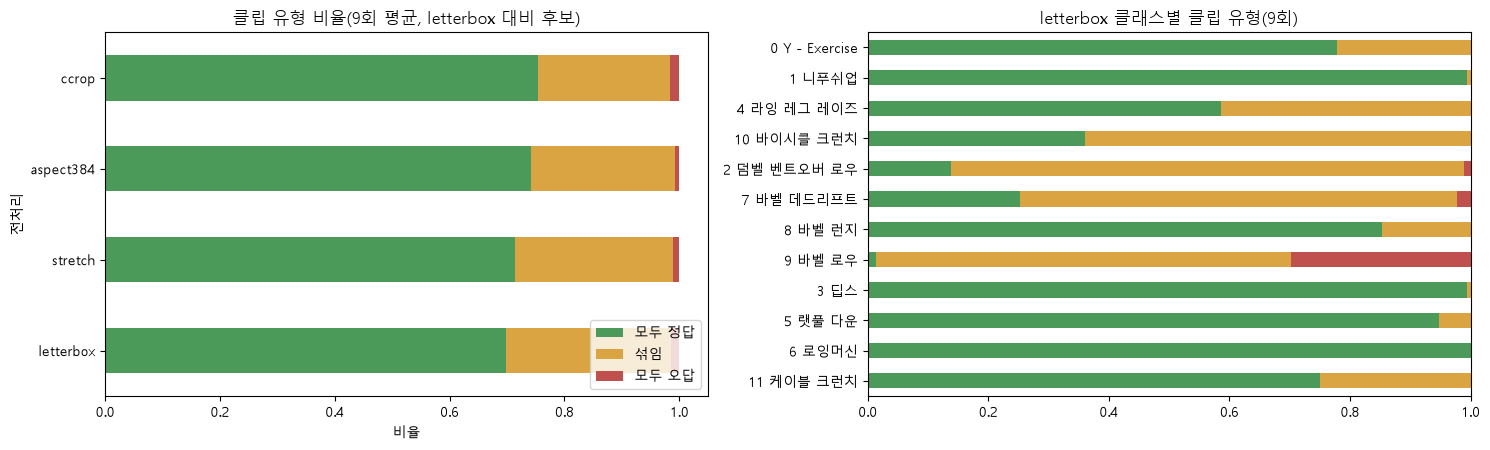

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
typ[["모두 정답", "섞임", "모두 오답"]].plot.barh(stacked=True, ax=axes[0], color=["#4c9a5a", "#d9a441", "#c0504d"])
axes[0].set_title("클립 유형 비율(9회 평균, letterbox 대비 후보)"); axes[0].set_xlabel("비율"); axes[0].legend(loc="lower right")
bycls[["모두_정답", "섞임", "모두_오답"]].plot.barh(stacked=True, ax=axes[1], color=["#4c9a5a", "#d9a441", "#c0504d"], legend=False)
axes[1].invert_yaxis(); axes[1].set_title("letterbox 클래스별 클립 유형(9회)")
plt.tight_layout(); plt.savefig(FIGURES / "ana_clip_consistency.png", dpi=110); plt.show()

## A4. 장수를 맞춘 비교: 다른 각도 2장 vs 다른 순간 2장(H1 재검토)

13번 노트북의 cam4는 "같은 카메라 4장"이 아니라 실제로 같은 카메라 1~2장이었습니다(A3에서 구조 확인). 그래서 clip8(8장)과 cam4(1~2장)의 차이에는 장수 차이가 섞여 있습니다. 여기서는 장수를 2장으로 맞춥니다.

- 대상: 같은 카메라 2장 묶음에 속한 이미지(클립마다 6장)
- 다중 시점: 같은 순간(frame_no)·다른 카메라 2장의 확률 평균 → Δ_view
- 다중 순간: 같은 카메라·다른 순간 2장의 확률 평균 → Δ_time
- 기준(계산 전 PLAN 보완): 9개 실행 중 7개 이상에서 한쪽이 크고 평균 차이 ≥ 0.005이면 그쪽이 더 도움, 그 밖은 구분되지 않음

In [10]:
mf1 = lambda y, p: f1_score(y, p, labels=list(range(12)), average="macro", zero_division=0)  # noqa: E731
PCOLS = [f"p{c}" for c in range(12)]

def smooth(d, keys):
    return d.groupby(keys)[PCOLS].transform("mean").to_numpy().argmax(1)

rows = []
for (p, s, f), d in cv.groupby(["전처리", "seed", "fold"]):
    d = d.reset_index(drop=True)
    view, time_, clip8 = smooth(d, ["clip_id", "frame_no"]), smooth(d, ["clip_id", "camera"]), smooth(d, "clip_id")
    sub = (d.groupby(["clip_id", "camera"]).image_id.transform("size") == 2).to_numpy()
    y = d.target_id.to_numpy()
    base = mf1(y[sub], d.pred.to_numpy()[sub])
    rows.append({"전처리": p, "seed": s, "fold": f, "대상 비율": sub.mean(), "이미지 F1": base,
                 "Δ_view(같은 순간·다른 카메라)": mf1(y[sub], view[sub]) - base, "Δ_time(같은 카메라·다른 순간)": mf1(y[sub], time_[sub]) - base,
                 "Δ_clip8(참고)": mf1(y[sub], clip8[sub]) - base})
a4 = pd.DataFrame(rows)
a4["view−time"] = a4["Δ_view(같은 순간·다른 카메라)"] - a4["Δ_time(같은 카메라·다른 순간)"]
a4s = a4.groupby("전처리").agg(**{"Δ_view 평균": ("Δ_view(같은 순간·다른 카메라)", "mean"), "Δ_time 평균": ("Δ_time(같은 카메라·다른 순간)", "mean"),
                                "Δ_clip8 평균": ("Δ_clip8(참고)", "mean"), "view−time 평균": ("view−time", "mean"),
                                "view>time 실행": ("view−time", lambda v: int((v > 0).sum())), "time>view 실행": ("view−time", lambda v: int((v < 0).sum()))}).reindex(PRE)
def verdict(r):
    if r["view>time 실행"] >= 7 and r["view−time 평균"] >= 0.005: return "다른 각도가 더 도움"
    if r["time>view 실행"] >= 7 and r["view−time 평균"] <= -0.005: return "다른 순간이 더 도움"
    return "구분되지 않음"
a4s["판정"] = a4s.apply(verdict, axis=1)
print("대상 비율(이미지 중):", a4["대상 비율"].round(3).unique())
a4s.round(4)

대상 비율(이미지 중): [0.75]


,Δ_view 평균,Δ_time 평균,Δ_clip8 평균,view−time 평균,view>time 실행,time>view 실행,판정
전처리,,,,,,,
letterbox,0.0118,0.0139,0.0534,-0.0021,3,6,구분되지 않음
stretch,0.0133,0.0167,0.0514,-0.0034,3,6,구분되지 않음
aspect384,0.0094,0.0151,0.0396,-0.0057,4,5,구분되지 않음
ccrop,0.0125,0.0112,0.0428,0.0013,3,6,구분되지 않음


## 해석(2026-11-26)

### A1. 성능 차이는 전처리·seed보다 "어느 묶음의 누구냐"에서 훨씬 크게 납니다
- 묶음별 사람 점수(letterbox): 기구 0.986, 맨몸 0.916, **바벨·덤벨 0.649**. 사람 점수가 0.80 미만인 6명은 전처리와 상관없이 모두 바벨·덤벨 묶음의 6명입니다.
- 사람 사이 흩어짐(sd 0.13~0.15)이 같은 사람의 seed 사이 흩어짐(0.014~0.025)보다 6~10배 큽니다. 운동마다 검증 사람이 한 명이면 결론이 그 사람에게 끌려가는 이유를 수치로 보여 줍니다(12·14번 노트북과 같은 결론).
- 사람을 크게 보는 전처리의 이득은 사람마다 다릅니다. Z17(0.62→0.77·0.78)과 Z19(0.58→0.67·0.68)는 크게 올랐고, Z21(0.69→0.68·0.71)과 공식 Val의 Z23(0.67→0.69·0.67)은 거의 그대로입니다.
- 바벨·덤벨 6명은 모두 같은 4운동(덤벨 로우·데드리프트·런지·바벨 로우)을 가졌습니다. 그래서 이 차이는 "가진 운동이 달라서"가 아니라 사람(체형·자세 습관·촬영 위치)에 따른 차이입니다.

### A2. 오답의 99.7% 이상이 같은 묶음 안에서 납니다
- CV 36회 오답 중 묶음 밖 오답은 전처리마다 2~10장뿐입니다(9회 합계, 오답 2,391~3,413장 중). 공식 Val에서는 E01(Scratch)과 E04(Full) 모두 100%가 묶음 안 오답입니다.
- Scratch는 오답이 더 많지만(291 vs 193장) 묶음 밖으로는 하나도 틀리지 않았습니다. 미리 적은 기준대로라면 "배경·공간으로 묶음까지는 가고, 그 안의 동작 구분이 약하다"는 가설과 맞습니다(Grad-CAM과 같은 방향).
- 다만 같은 묶음의 운동은 배경뿐 아니라 동작도 비슷합니다. 그래서 이 결과만으로 배경 때문인지 동작이 비슷해서인지는 가를 수 없습니다. 둘을 가르려면 배경을 가린 입력 같은 별도 실험이 필요합니다.

### A3. 클립 8장 일관성: 바벨 로우는 클립의 30%를 통째로 틀립니다
- **클립 구조 정정**: 한 클립 8장은 4개 시점 × 시점마다 서로 다른 카메라 2대이고, 카메라는 5대입니다(카메라마다 1~2장). 그동안 "카메라 2대 × 4시점"으로 잘못 알고 있었습니다.
- letterbox 클립의 70%는 8장을 모두 맞히고 29%는 섞여 있으며, 1.5%는 모두 틀립니다. 그런데 **바벨 로우는 모두 맞힌 클립이 1.4%, 모두 틀린 클립이 30%**입니다. 확률을 평균해도 바벨 로우가 풀리지 않은 이유(13번 H1)가 여기 있습니다. 틀리는 쪽으로 일관되면 평균해도 틀립니다.
- 바벨·덤벨 묶음에서는 **같은 순간을 다른 카메라로 본 2장**의 예측이, 같은 카메라로 다른 순간을 본 2장보다 더 자주 달랐습니다(바벨 로우 일치 0.45 vs 0.64, 덤벨 로우 0.56 vs 0.69, 데드리프트 0.64 vs 0.71). 이 묶음에서는 예측이 동작의 순간보다 **찍은 각도**에 더 좌우됩니다. 오답이 클래스 × 카메라 칸에 몰린다는 E06 관찰과 맞습니다.
- ccrop은 모두 맞힌 클립이 가장 많지만(75.5%), 모두 틀린 클립도 가장 많습니다(1.7%). 평균은 오르는데 바벨 로우는 무너지는 2단계 결과와 같은 모습입니다.

### A4. clip8의 이득은 주로 "본 장수"에서 나왔습니다(13번 H1 해석 정정)
- 장수를 2장으로 맞추면, 다른 각도 2장(Δ_view +0.009~+0.013)과 다른 순간 2장(Δ_time +0.011~+0.017)이 비슷했습니다. 네 전처리 모두 "구분되지 않음"입니다(미리 정한 7/9·0.005 기준에 어느 쪽도 닿지 않음).
- 같은 이미지 묶음에서 8장 평균은 +0.040~+0.053입니다. 2장 평균의 3~4배입니다. 정리하면 **같은 클립 사진을 더 많이 볼수록 좋아지고, 각도와 순간 중 어느 쪽이 특별히 더 낫지는 않았습니다.**
- 그래서 13번 노트북의 "이득은 카메라 두 대를 합친 데서 나왔다"는 해석은 철회합니다. 그때 비교한 cam4는 같은 카메라 4장이 아니라 1~2장이어서, 장수 차이가 섞여 있었습니다. H1의 사전 판정("지지")은 클립 단위 정의라 바뀌지 않습니다.
- A3과 함께 보면, 바벨·덤벨 묶음에서는 각도가 바뀌면 예측도 자주 바뀝니다. 하지만 평균했을 때 맞는 쪽으로 더 끌어 주는 것은 아니었습니다.

### 한계
- 진단 분석이라 결과로 전처리·모델 선택을 바꾸지 않습니다. CV 점수는 Early Stopping과 같은 데이터에서 나와 낙관적입니다.
- 추론 배치를 학습 때 평가와 같은 32로 맞췄습니다. 배치 64로 추론했을 때 fp16 계산 차이로 실행 4개에서 확률 0.5 미만의 애매한 사진이 1장씩 다르게 예측됐습니다(그때 기록과의 차이 ≤ 0.0006). 배치 32에서는 36개 실행 모두 학습 기록의 F1과 같았습니다.